# 스마트 팩토리 데이터 분석

### 이 노트북에서 할 일

공장의 설비와 생산 기록을 살펴보고, **나중에 어떤 모니터링 프로그램을 만들지** 생각합니다. 코드를 모두 외울 필요는 없습니다. 각 작은 단계에서 아래 순서를 따라가세요.

**① 이번에 할 일 읽기 → ② AI에게 요청할 문장 살펴보기 → ③ 코드 실행 → ④ 결과 보는 법 읽기**

### Colab에서 시작하기

1. [Google Colab](https://colab.research.google.com/)을 열고 **파일 → 노트 업로드**에서 이 `.ipynb` 파일을 선택합니다.
2. Colab 왼쪽의 **폴더 모양 아이콘(파일)**을 누릅니다. 파일 창에서 **세션 저장소에 업로드** 버튼을 눌러 `machine_info.csv`와 `production_data.csv`를 둘 다 업로드합니다. 두 파일 이름을 정확하게 유지하세요.
3. 첫 번째 코드부터 차례대로 클릭하고 `Shift + Enter`를 누릅니다. 이전 코드의 결과를 다음 코드가 사용합니다. 메뉴의 **런타임 → 모두 실행**도 사용할 수 있습니다.
4. Colab 런타임이 종료되거나 초기화되면 임시로 올린 CSV가 사라질 수 있습니다. 다시 연결한 다음 두 파일을 다시 업로드하세요. 노트북은 Google Drive에 사본을 저장할 수 있습니다.
5. GPU는 필요하지 않습니다. 분석에 필요한 패키지는 Colab에 대부분 설치되어 있습니다. 패키지가 없다는 오류가 나면 새 코드 셀에서 `%pip install pandas numpy matplotlib seaborn scipy`를 실행한 뒤 처음부터 다시 실행하세요.

**로컬 Jupyter/VS Code에서 실행한다면:** 노트북과 두 CSV를 같은 작업 폴더에 두고 실행하세요. 로컬 파일을 Colab에 자동으로 접근할 수는 없습니다.

| 처음 보는 말 | 뜻 |
|---|---|
| 데이터 | 컴퓨터에 저장된 기록입니다. |
| 행 | 표의 가로 한 줄입니다. 생산 파일에서는 기록 한 건입니다. |
| 열 | 표의 세로 항목입니다. 예: 설비 번호, 온도 |
| 설비 마스터 | 공장에 등록된 설비의 기본 정보 목록입니다. |
| 관측 | 어떤 시각에 기록된 값입니다. |
| 결측 | 값이 비어 있는 것입니다. |

**먼저 확인할 가정:** 이 분석은 `production_count`가 일정 구간 동안 새로 생산한 수량이고, `defect_count`가 그 안에 포함된 불량 수량이라고 가정합니다. 값이 누적 수량이면 계산 방법이 달라집니다. 기록 시각의 시간대와 온도·습도의 단위도 원본만으로 확정할 수 없습니다. 실제 사용 전에 현장에 확인하세요. 원본 CSV는 수정하지 않습니다.


### 두 파일의 열 알아보기

분석을 시작하기 전에 표의 각 열이 무엇을 나타내는지 살펴봅니다. 아래 뜻은 열 이름을 바탕으로 정리했습니다. **측정 단위, 수량이 구간별 값인지 누적값인지, 시간대는 현장 확인이 필요합니다.**

| 파일 | 열 이름 | 쉽게 말하면 |
|---|---|---|
| 설비 정보 | `machine_id` | 설비마다 붙은 번호. 두 표를 연결할 때 사용합니다. |
| 설비 정보 | `machine_name` | 사람이 읽기 쉬운 설비 이름 |
| 설비 정보 | `location` | 설비가 속한 라인 또는 위치 |
| 설비 정보 | `temperature_limit` | 설비마다 설정된 온도 한계값 |
| 생산 기록 | `timestamp` | 기록된 날짜와 시각 |
| 생산 기록 | `machine_id` | 기록을 남긴 설비의 번호 |
| 생산 기록 | `product_id` | 해당 기록의 제품 번호 |
| 생산 기록 | `production_count` | 생산 수량. 이 노트북에서는 구간별 수량이라고 가정합니다. |
| 생산 기록 | `defect_count` | 불량 수량. 생산 수량에 포함된다고 가정합니다. |
| 생산 기록 | `temperature` | 기록된 온도 |
| 생산 기록 | `humidity` | 기록된 습도 |
| 생산 기록 | `operating_status` | 기록 시점의 설비 상태 |


## 1. 분석 준비하기

먼저 분석에 필요한 도구를 준비하고 파일을 읽습니다.

### 1-1. 도구 불러오기

**개념 한 걸음:** 라이브러리는 다른 사람이 미리 만들어 둔 도구 모음입니다. `pandas`는 표, `matplotlib`과 `seaborn`은 그래프를 다룹니다.

**이번에 할 일:** 표를 읽고 그래프를 그리는 파이썬 도구를 불러옵니다.

**AI에게 요청할 문장** — 아래 문장을 복사해서 바이브 코딩 도구에 입력할 수 있습니다. 이전 셀을 순서대로 실행한 상태라고 알려 주세요.

```text
pandas, numpy, matplotlib, seaborn, scipy 등 데이터 분석에 필요한 라이브러리를 불러와 주세요.
```

**코드:** 아래 셀을 클릭하고 `Shift + Enter`를 누르세요.

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import seaborn as sns
from scipy import stats
from IPython.display import display, Markdown

**결과 보는 법:** `import`는 미리 만들어진 도구를 가져오라는 뜻입니다. 오류가 없다면 보통 출력이 없습니다.

### 1-2. 표와 그래프 설정하기

**이번에 할 일:** 표의 숫자를 읽기 쉽게 표시하고, 그래프에서 한글을 사용할 수 있게 설정합니다.

**AI에게 요청할 문장** — 아래 문장을 복사해서 바이브 코딩 도구에 입력할 수 있습니다. 이전 셀을 순서대로 실행한 상태라고 알려 주세요.

```text
Colab에서는 나눔고딕 글꼴이 없으면 설치하고 현재 세션에 등록하세요. 로컬에서는 설치된 한글 글꼴을 찾아 pandas 표와 matplotlib·seaborn 그래프를 읽기 쉽게 설정하세요.
```

**코드:** 아래 셀을 클릭하고 `Shift + Enter`를 누르세요.

In [2]:
import sys
import subprocess
from pathlib import Path

# Colab인지 확인합니다. 로컬에서는 패키지 설치를 시도하지 않습니다.
IN_COLAB = 'google.colab' in sys.modules
nanum_path = Path('/usr/share/fonts/truetype/nanum/NanumGothic.ttf')
if IN_COLAB and not nanum_path.exists():
    print('한글 그래프를 위해 나눔고딕 글꼴을 설치합니다. 잠시 기다려 주세요.')
    try:
        subprocess.run(['apt-get', 'update', '-qq'], check=True, stdout=subprocess.DEVNULL)
        subprocess.run(['apt-get', 'install', '-y', '-qq', 'fonts-nanum'], check=True, stdout=subprocess.DEVNULL)
    except (OSError, subprocess.CalledProcessError):
        print('한글 글꼴 설치에 실패했습니다. 네트워크를 확인한 뒤 이 셀을 다시 실행하세요.')

pd.set_option('display.max_columns', 30)
pd.set_option('display.max_rows', 30)
pd.options.display.float_format = '{:,.3f}'.format

# 새로 설치한 글꼴을 이 런타임에 바로 등록합니다.
if nanum_path.exists():
    fm.fontManager.addfont(str(nanum_path))
available_fonts = {f.name for f in fm.fontManager.ttflist}
font = next((x for x in ['NanumGothic', 'Malgun Gothic', 'AppleGothic'] if x in available_fonts), None)
if font:
    print(f'그래프 글꼴: {font}')
else:
    print('한글 글꼴을 찾지 못했습니다. 그래프의 한글이 깨질 수 있습니다.')
sns.set_theme(style='whitegrid', font=font or 'sans-serif', rc={'axes.unicode_minus': False})

그래프 글꼴: Malgun Gothic


**결과 보는 법:** `그래프 글꼴: NanumGothic`이 표시되면 Colab에서 한글 글꼴을 사용할 준비가 된 것입니다. 설치에 실패하면 네트워크를 확인하고 이 셀을 다시 실행하세요. 로컬에서는 설치된 한글 글꼴을 사용합니다.

### 1-3. CSV 파일 읽기

**이번에 할 일:** Colab의 파일 창에 업로드한 두 파일을 표로 읽고 앞의 다섯 줄을 확인합니다. 로컬에서는 현재 작업 폴더를 사용합니다.

**AI에게 요청할 문장** — 아래 문장을 복사해서 바이브 코딩 도구에 입력할 수 있습니다. 이전 셀을 순서대로 실행한 상태라고 알려 주세요.

```text
Colab의 /content 또는 로컬 작업 폴더에서 machine_info.csv와 production_data.csv를 pandas로 읽고 설비 번호와 제품 번호는 문자로 다뤄 주세요. 각 표의 크기와 앞의 다섯 행을 표시하세요.
```

**코드:** 아래 셀을 클릭하고 `Shift + Enter`를 누르세요.

In [3]:
# Colab에서는 파일 창에 업로드한 /content 폴더를 사용합니다.
# 로컬에서는 노트북을 실행한 현재 작업 폴더를 사용합니다.
ROOT = Path('/content') if IN_COLAB else Path.cwd()
required_files = ['machine_info.csv', 'production_data.csv']
missing_files = [name for name in required_files if not (ROOT / name).is_file()]

if missing_files:
    raise FileNotFoundError(
        f"다음 파일을 찾지 못했습니다: {', '.join(missing_files)}. "
        f"Colab 왼쪽 파일 창에서 두 CSV를 업로드하세요. 확인한 폴더: {ROOT}"
    )

machine = pd.read_csv(ROOT / 'machine_info.csv', encoding='utf-8-sig', dtype={'machine_id': 'string'})
production = pd.read_csv(ROOT / 'production_data.csv', encoding='utf-8-sig', dtype={'machine_id': 'string', 'product_id': 'string'})
print('설비 정보 (행, 열):', machine.shape)
print('생산 기록 (행, 열):', production.shape)
display(machine.head(), production.head())

설비 정보 (행, 열): (10000, 4)
생산 기록 (행, 열): (10000, 8)


,machine_id,machine_name,location,temperature_limit
0,M001,프레스 1호기,A라인,40
1,M002,프레스 2호기,A라인,40
2,M003,조립 1호기,B라인,40
3,M004,조립 2호기,B라인,40
4,M005,프레스 3호기,A라인,40


,timestamp,machine_id,product_id,production_count,defect_count,temperature,humidity,operating_status
0,2026-11-01 00:00,M001,P001,89,3,36.400,67.300,RUNNING
1,2026-11-01 00:00,M002,P002,148,4,35.600,74.800,RUNNING
2,2026-11-01 00:00,M003,P003,129,3,34.400,41.800,RUNNING
3,2026-11-01 00:00,M004,P004,173,1,34.200,47.200,RUNNING
4,2026-11-01 00:00,M005,P005,90,4,39.500,63.800,RUNNING


**결과 보는 법:** `(행 수, 열 수)`가 표의 크기입니다. 위 표는 설비 목록, 아래 표는 생산 기록입니다. `head()`는 앞의 다섯 줄만 보여 줍니다.

## 2. 데이터가 제대로 들어왔는지 확인하기

값이 비었거나 같은 기록이 반복되면 분석 결과가 달라질 수 있습니다. 발견된 후보는 바로 지우지 않고 먼저 확인합니다.

### 2-1. 빈칸 확인하기

**개념 한 걸음:** 결측값은 기록이 비어 있어 값을 알 수 없는 경우입니다. 실제로 측정된 숫자 0과는 다릅니다.

**이번에 할 일:** 각 열에 빈칸이 몇 개 있는지 확인합니다.

**AI에게 요청할 문장** — 아래 문장을 복사해서 바이브 코딩 도구에 입력할 수 있습니다. 이전 셀을 순서대로 실행한 상태라고 알려 주세요.

```text
machine과 production의 각 열에 대해 자료형과 결측값 개수를 표로 보여 주세요.
```

**코드:** 아래 셀을 클릭하고 `Shift + Enter`를 누르세요.

In [4]:
print('마스터 자료형 및 결측')
display(pd.DataFrame({'자료형': machine.dtypes.astype(str), '결측수': machine.isna().sum()}))
print('생산 이력 자료형 및 결측')
display(pd.DataFrame({'자료형': production.dtypes.astype(str), '결측수': production.isna().sum()}))

마스터 자료형 및 결측


,자료형,결측수
machine_id,string,0
machine_name,str,0
location,str,0
temperature_limit,int64,0


생산 이력 자료형 및 결측


,자료형,결측수
timestamp,str,0
machine_id,string,0
product_id,string,0
production_count,int64,0
defect_count,int64,0
temperature,float64,0
humidity,float64,0
operating_status,str,0


**결과 보는 법:** `결측수`가 0이면 해당 열의 값이 비어 있는 행이 없다는 뜻입니다. 자료형은 숫자, 문자 등의 종류입니다.

### 2-2. 중복과 이상한 값 확인하기

**개념 한 걸음:** 중복은 같은 기준으로 보았을 때 기록이 반복된 것입니다. 제품이 다른 두 행까지 같은 기록으로 지우지 않도록 확인합니다.

**이번에 할 일:** 같은 기록, 잘못된 시각, 수량 오류 후보를 셉니다.

**AI에게 요청할 문장** — 아래 문장을 복사해서 바이브 코딩 도구에 입력할 수 있습니다. 이전 셀을 순서대로 실행한 상태라고 알려 주세요.

```text
생산 시각을 날짜·시간으로 변환하고, 마스터 키 중복, 시각·설비·제품 중복, 수량 오류, 비가동 중 생산, 미등록 설비 등의 건수를 확인해 checks에 저장해 주세요. 오류 후보를 자동 삭제하지 마세요.
```

**코드:** 아래 셀을 클릭하고 `Shift + Enter`를 누르세요.

In [5]:
production = production.copy()
production['timestamp_parsed'] = pd.to_datetime(production['timestamp'], errors='coerce')
checks = pd.Series({
    '마스터 전체 행 중복': machine.duplicated().sum(),
    '마스터 설비 ID 결측': machine.machine_id.isna().sum(),
    '마스터 설비 ID 중복': machine.machine_id.duplicated().sum(),
    '생산 전체 행 중복': production.duplicated().sum(),
    '생산 시각 변환 실패': production.timestamp_parsed.isna().sum(),
    '생산 설비 ID 결측': production.machine_id.isna().sum(),
    '시각·설비 중복': production.duplicated(['timestamp_parsed', 'machine_id']).sum(),
    '시각·설비·제품 중복': production.duplicated(['timestamp_parsed', 'machine_id', 'product_id']).sum(),
    '음수 생산 또는 불량': ((production.production_count < 0) | (production.defect_count < 0)).sum(),
    '불량이 생산보다 많은 행': (production.defect_count > production.production_count).sum(),
    '비가동 상태에서 생산량 양수': ((production.operating_status != 'RUNNING') & (production.production_count > 0)).sum(),
    '마스터에 없는 생산 행': (~production.machine_id.isin(machine.machine_id)).sum(),
}, name='건수')
display(checks.to_frame())

,건수
마스터 전체 행 중복,0
마스터 설비 ID 결측,0
마스터 설비 ID 중복,0
생산 전체 행 중복,0
생산 시각 변환 실패,0
생산 설비 ID 결측,0
시각·설비 중복,0
시각·설비·제품 중복,0
음수 생산 또는 불량,0
불량이 생산보다 많은 행,0


**결과 보는 법:** 숫자가 0보다 크면 원본을 확인해 볼 필요가 있습니다. 같은 설비·시각이라도 제품이 다르면 여러 줄이 정상일 수 있으니 무조건 삭제하지 않습니다.

### 2-3. 설비 상태 확인하기

**이번에 할 일:** 각 상태가 몇 번 기록됐는지 확인합니다.

**AI에게 요청할 문장** — 아래 문장을 복사해서 바이브 코딩 도구에 입력할 수 있습니다. 이전 셀을 순서대로 실행한 상태라고 알려 주세요.

```text
production에서 operating_status별 기록 건수를 세어 주세요.
```

**코드:** 아래 셀을 클릭하고 `Shift + Enter`를 누르세요.

In [6]:
print('상태별 행 수')
display(production.operating_status.value_counts(dropna=False).to_frame('건수'))

상태별 행 수


,건수
operating_status,
RUNNING,8958
STOPPED,733
MAINTENANCE,309


**결과 보는 법:** `RUNNING`은 가동, `STOPPED`는 정지, `MAINTENANCE`는 보전 상태 기록입니다. 숫자는 시간이나 설비 대수가 아닌 기록 건수입니다.

### 2-4. 두 표 연결하기

**개념 한 걸음:** 병합은 두 표의 공통 열을 이용해 정보를 붙이는 일입니다. 학생 번호로 출석표와 학생 명단을 연결하는 것과 같습니다. `left join`은 기준이 되는 왼쪽 표의 행을 남깁니다.

**이번에 할 일:** 설비 번호를 기준으로 생산 기록에 설비 이름과 라인을 붙입니다.

**AI에게 요청할 문장** — 아래 문장을 복사해서 바이브 코딩 도구에 입력할 수 있습니다. 이전 셀을 순서대로 실행한 상태라고 알려 주세요.

```text
마스터 설비 번호가 비어 있거나 중복되면 오류를 내고, machine_id로 production과 machine을 many-to-one left join해 df를 만드세요. 병합 전후 행 수와 매칭 결과를 보여 주세요.
```

**코드:** 아래 셀을 클릭하고 `Shift + Enter`를 누르세요.

In [7]:
if machine.machine_id.isna().any() or machine.machine_id.duplicated().any():
    raise ValueError('마스터 설비 ID가 결측 또는 중복입니다. 원인을 해결하고 다시 실행하세요.')
df = production.merge(machine, on='machine_id', how='left', validate='many_to_one', indicator=True)
print('병합 전/후 행 수:', len(production), '/', len(df))
display(df['_merge'].value_counts(dropna=False).to_frame('행 수'))

병합 전/후 행 수: 10000 / 10000


,행 수
_merge,
both,10000
left_only,0
right_only,0


**결과 보는 법:** 병합 전후 행 수가 같아야 생산 기록이 불어나지 않은 것입니다. `left_only`가 있으면 설비 목록과 연결되지 않은 생산 기록입니다.

## 3. 기록 범위 확인하기

공장에 등록된 설비와 실제 기록이 남은 설비는 다를 수 있습니다.

### 3-1. 기간과 설비 수 확인하기

**이번에 할 일:** 기록 시작·끝 시각과 등록·관측 설비 수를 확인합니다.

**AI에게 요청할 문장** — 아래 문장을 복사해서 바이브 코딩 도구에 입력할 수 있습니다. 이전 셀을 순서대로 실행한 상태라고 알려 주세요.

```text
df를 설비와 시간 순으로 정렬하고 관측 기간, 등록 설비 수, 관측 설비 수, 이력이 없는 등록 설비 수를 출력해 주세요.
```

**코드:** 아래 셀을 클릭하고 `Shift + Enter`를 누르세요.

In [8]:
df = df.sort_values(['machine_id', 'timestamp_parsed']).copy()
df['interval_hours'] = df.groupby('machine_id')['timestamp_parsed'].diff().dt.total_seconds() / 3600
print('관측 기간:', df.timestamp_parsed.min(), '~', df.timestamp_parsed.max(), '(시간대 정보 미확인)')
print('마스터 설비:', machine.machine_id.nunique(), '대 / 관측 설비:', df.machine_id.nunique(), '대 / 이력 없는 마스터:', (~machine.machine_id.isin(df.machine_id)).sum(), '대')

관측 기간: 2026-11-01 00:00:00 ~ 2026-11-05 03:00:00 (시간대 정보 미확인)
마스터 설비: 10000 대 / 관측 설비: 100 대 / 이력 없는 마스터: 9900 대


**결과 보는 법:** 이력이 없는 설비는 기록이 없을 뿐입니다. 멈췄는지, 수집 대상이 아니었는지는 알 수 없습니다. 시각의 시간대도 확인되지 않았습니다.

### 3-2. 기록 간격 확인하기

**이번에 할 일:** 같은 설비에서 다음 기록까지 몇 시간 걸렸는지 살펴봅니다.

**AI에게 요청할 문장** — 아래 문장을 복사해서 바이브 코딩 도구에 입력할 수 있습니다. 이전 셀을 순서대로 실행한 상태라고 알려 주세요.

```text
설비별 연속 기록 간격의 빈도와 설비별 기록 건수의 분포를 표시해 주세요.
```

**코드:** 아래 셀을 클릭하고 `Shift + Enter`를 누르세요.

In [9]:
print('설비별 연속 기록 간격(시간) 상위 빈도')
display(df.interval_hours.value_counts(dropna=False).head(10).to_frame('건수'))
display(df.groupby('machine_id').size().describe().to_frame('설비별 기록 수'))

설비별 연속 기록 간격(시간) 상위 빈도


,건수
interval_hours,
1.000,9900
NaN,100


,설비별 기록 수
count,100.000
mean,100.000
std,0.000
min,100.000
25%,100.000
50%,100.000
75%,100.000
max,100.000


**결과 보는 법:** 예를 들어 간격이 1이면 두 기록 사이가 한 시간이라는 뜻입니다. 첫 기록에는 이전 기록이 없어 간격이 비어 있습니다. 기록 기간 바깥의 누락은 알 수 없습니다.

## 4. 생산과 불량의 전체 모습

**불량률 = 불량 수량 ÷ 생산 수량 × 100**입니다. 100개 중 3개가 불량이면 불량률은 3%입니다. 전체 불량률은 불량의 합을 생산의 합으로 나눕니다.

### 4-1. 전체 숫자 계산하기

**개념 한 걸음:** 비율은 전체 중 일부가 차지하는 몫입니다. 불량률은 `불량 합 ÷ 생산 합 × 100`으로 계산합니다. 생산량이 0이면 나눌 수 없어 불량률도 정할 수 없습니다.

**이번에 할 일:** 생산량, 불량률, 상태와 온도 초과 비율을 계산합니다.

**AI에게 요청할 문장** — 아래 문장을 복사해서 바이브 코딩 도구에 입력할 수 있습니다. 이전 셀을 순서대로 실행한 상태라고 알려 주세요.

```text
df에 날짜, 시간, 온도 한계 초과 여부와 행별 불량률을 추가하고 전체 생산량, 불량 수량, 가중 불량률, RUNNING 관측 비율, 온도 한계 초과 관측 비율을 계산해 주세요. 분모가 0이면 미계산으로 두세요.
```

**코드:** 아래 셀을 클릭하고 `Shift + Enter`를 누르세요.

In [10]:
df['date'] = df.timestamp_parsed.dt.date
df['hour'] = df.timestamp_parsed.dt.hour
df['temp_excess'] = np.where(df.temperature.notna() & df.temperature_limit.notna(), df.temperature > df.temperature_limit, np.nan)
df['row_defect_rate'] = np.where(df.production_count > 0, df.defect_count / df.production_count * 100, np.nan)
total_prod, total_def = df.production_count.sum(min_count=1), df.defect_count.sum(min_count=1)
overall_rate = total_def / total_prod * 100 if total_prod > 0 else np.nan
kpis = pd.Series({'생산 기록 수': len(df), '총 생산량': total_prod, '총 불량 수량': total_def,
                  '전체 불량률 (%)': overall_rate, 'RUNNING 관측 비율 (%)': df.operating_status.eq('RUNNING').mean()*100,
                  '온도 한계 초과 관측 비율 (%)': df.temp_excess.mean()*100}, name='값')
display(kpis.to_frame())

,값
생산 기록 수,"10,000.000"
총 생산량,"1,118,576.000"
총 불량 수량,"38,088.000"
전체 불량률 (%),3.405
RUNNING 관측 비율 (%),89.580
온도 한계 초과 관측 비율 (%),27.450


**결과 보는 법:** 온도 초과는 측정 온도가 그 설비의 한계보다 클 때입니다. 한계와 정확히 같으면 초과가 아닙니다. RUNNING 관측 비율은 기록의 비율이며 실제 시간 가동률이나 OEE가 아닙니다.

### 4-2. 숫자의 범위 확인하기

**이번에 할 일:** 평균과 가장 작고 큰 값을 확인합니다.

**AI에게 요청할 문장** — 아래 문장을 복사해서 바이브 코딩 도구에 입력할 수 있습니다. 이전 셀을 순서대로 실행한 상태라고 알려 주세요.

```text
생산량, 불량 수, 온도, 습도의 기초 통계량을 표로 보여 주세요.
```

**코드:** 아래 셀을 클릭하고 `Shift + Enter`를 누르세요.

In [11]:
display(df[['production_count', 'defect_count', 'temperature', 'humidity']].describe(percentiles=[.05,.25,.5,.75,.95]).T)

,count,mean,std,min,5%,25%,50%,75%,95%,max
production_count,"10,000.000",111.858,48.635,0.000,0.000,88.000,118.000,149.000,174.000,180.000
defect_count,"10,000.000",3.809,3.667,0.000,0.000,1.000,3.000,6.000,11.000,27.000
temperature,"10,000.000",36.608,4.756,22.000,26.300,33.900,37.100,40.400,42.900,43.500
humidity,"10,000.000",54.988,11.643,35.000,36.900,44.700,55.100,65.100,73.100,75.000


**결과 보는 법:** `mean`은 평균, `min`은 최솟값, `max`는 최댓값입니다. 평균만 보면 극단적인 값이나 넓은 범위를 놓칠 수 있습니다.

## 4-2 추가 학습. 기초 통계로 숫자를 자세히 살펴보기

통계는 많은 숫자의 특징을 간단하게 설명하는 방법입니다. 예를 들어 생산 수량이 `10, 10, 10, 10, 60`이면 평균은 **20**이지만 중앙값은 **10**입니다. 숫자 하나가 아주 크면 평균이 영향을 받으므로 두 값을 함께 보면 좋습니다.

아래 분석은 **생산 기록 한 행을 한 번의 관측**으로 봅니다. 같은 설비가 여러 번 기록되므로 관측들이 서로 완전히 독립이라고 가정하지 않습니다. 행별 통계는 전체 공장의 시간당 생산량이 아닙니다.

### 기초 통계 ① 유효한 기록과 대표값

**개념을 쉽게 이해하기:** **평균**은 값의 합을 값의 개수로 나눈 수입니다. **중앙값**은 값을 작은 순서로 놓았을 때 가운데 값입니다. 값의 개수가 짝수이면 가운데 두 값의 평균을 사용합니다. **유효 개수**는 빈칸을 제외하고 계산에 사용한 값의 수입니다.

**AI에게 요청할 문장**
```text
df의 production_count, defect_count, temperature, humidity 각각에 대해 결측이 아닌 값의 개수, 평균, 중앙값, 최솟값, 최댓값을 계산해 한글 열 이름의 표로 보여 주세요. 분석 단위는 생산 기록 한 행입니다.
```

**코드 실행:** 아래 셀을 클릭하고 `Shift + Enter`를 누르세요.

In [12]:
# 숫자 네 가지를 선택합니다.
basic_columns = ['production_count', 'defect_count', 'temperature', 'humidity']

# 각 열을 기준으로 대표값을 계산합니다. pandas는 빈칸을 제외합니다.
basic_stats = df[basic_columns].agg(['count', 'mean', 'median', 'min', 'max']).T
basic_stats.columns = ['유효 개수', '평균', '중앙값', '최솟값', '최댓값']
display(basic_stats)

,유효 개수,평균,중앙값,최솟값,최댓값
production_count,"10,000.000",111.858,118.000,0.000,180.000
defect_count,"10,000.000",3.809,3.000,0.000,27.000
temperature,"10,000.000",36.608,37.100,22.000,43.500
humidity,"10,000.000",54.988,55.100,35.000,75.000


**결과 읽기:** 한 행은 하나의 변수입니다. 평균과 중앙값이 많이 다르면 한쪽으로 치우친 값이나 큰 값이 있는지 그래프와 함께 확인하세요. 온도·습도의 단위는 확인 전이므로 원본 단위로 읽습니다.

### 기초 통계 ② 사분위수와 표준편차

**개념을 쉽게 이해하기:** **사분위수**는 숫자를 작은 순서로 놓고 네 부분으로 나누는 위치입니다. 1사분위수(Q1)는 아래에서 약 25%, 2사분위수는 중앙값, 3사분위수(Q3)는 아래에서 약 75% 위치의 값입니다. **사분위범위(IQR)**는 `Q3 - Q1`이며 가운데 절반의 퍼진 정도를 보여 줍니다. **표준편차**가 크면 값들이 평균에서 대체로 더 넓게 퍼져 있다는 뜻입니다.

**AI에게 요청할 문장**
```text
df의 production_count, defect_count, temperature, humidity에 대해 1사분위수, 중앙값, 3사분위수, 사분위범위와 표본 표준편차(ddof=1)를 계산해 보여 주세요. 결측값은 제외하세요.
```

**코드 실행:** 아래 셀을 클릭하고 `Shift + Enter`를 누르세요.

In [13]:
spread = df[basic_columns].quantile([0.25, 0.50, 0.75]).T
spread.columns = ['1사분위수(Q1)', '중앙값(Q2)', '3사분위수(Q3)']
spread['사분위범위(IQR)'] = spread['3사분위수(Q3)'] - spread['1사분위수(Q1)']
spread['표준편차'] = df[basic_columns].std(ddof=1)
display(spread)

,1사분위수(Q1),중앙값(Q2),3사분위수(Q3),사분위범위(IQR),표준편차
production_count,88.000,118.000,149.000,61.000,48.635
defect_count,1.000,3.000,6.000,5.000,3.667
temperature,33.900,37.100,40.400,6.500,4.756
humidity,44.700,55.100,65.100,20.400,11.643


**결과 읽기:** Q1이 30이고 Q3가 40이면 가운데 절반은 대략 30~40에 모여 있고 IQR은 10입니다. 표준편차는 각 변수의 단위와 크기에 영향을 받으므로 온도와 생산량의 숫자를 그대로 비교해 어느 쪽이 더 불안정하다고 말하지 않습니다.

### 기초 통계 ③ 생산 중인 기록만 따로 보기

**개념을 쉽게 이해하기:** 상태가 정지인 기록은 생산량이 0일 수 있습니다. 전체 기록의 평균에는 이런 0도 포함됩니다. 따라서 **전체 기록의 평균**과 **RUNNING이라고 기록된 행의 평균**을 각각 보면 차이를 이해하기 쉽습니다. 두 값 모두 한 행당 평균입니다.

**AI에게 요청할 문장**
```text
전체 행과 operating_status가 RUNNING인 행 각각에 대해 기록 수, 생산량 평균, 생산량 중앙값, 생산량 표준편차, 생산량 합계와 불량 합계를 구하고, 불량 합계 나누기 생산량 합계로 불량률을 계산해 비교해 주세요. 생산량이 0이면 불량률은 비워 주세요.
```

**코드 실행:** 아래 셀을 클릭하고 `Shift + Enter`를 누르세요.

In [14]:
# 서로 다른 두 집단을 만듭니다.
groups = {'전체 기록': df, 'RUNNING 기록': df[df['operating_status'] == 'RUNNING']}
comparison = []
for name, group in groups.items():
    made = group['production_count'].sum(min_count=1)
    defects = group['defect_count'].sum(min_count=1)
    comparison.append({
        '구분': name,
        '기록 수': len(group),
        '행별 생산량 평균': group['production_count'].mean(),
        '행별 생산량 중앙값': group['production_count'].median(),
        '행별 생산량 표준편차': group['production_count'].std(ddof=1),
        '생산량 합계': made,
        '불량 합계': defects,
        '가중 불량률(%)': defects / made * 100 if made > 0 else np.nan,
    })
display(pd.DataFrame(comparison).set_index('구분'))

,기록 수,행별 생산량 평균,행별 생산량 중앙값,행별 생산량 표준편차,생산량 합계,불량 합계,가중 불량률(%)
구분,,,,,,,
전체 기록,10000,111.858,118.000,48.635,1118576,38088,3.405
RUNNING 기록,8958,124.869,125.000,31.869,1118576,38088,3.405


**결과 읽기:** 전체 평균에는 모든 상태가 포함됩니다. RUNNING 평균은 RUNNING 행만 포함합니다. 두 평균이 다른 이유를 생각해 보세요. 실제 시간 가동률이나 설비 1대의 시간당 생산량으로 해석할 수는 없습니다. 가중 불량률은 불량 합계를 생산 합계로 나눈 값입니다.

### 기초 통계 ④ 상자그림으로 분포 보기

**개념을 쉽게 이해하기:** **상자그림**은 숫자의 퍼진 모습을 짧게 보여 주는 그림입니다. 상자의 아래와 위는 Q1과 Q3, 상자 안의 선은 중앙값입니다. 상자 밖 점은 정해진 기준에서 멀리 떨어진 **확인 후보**입니다. 후보라는 사실만으로 잘못된 값은 아닙니다.

**AI에게 요청할 문장**
```text
RUNNING인 기록의 행별 생산량을 상자그림으로 그려 주세요. 제목과 축 이름을 한글로 표시하고, 결과가 비어 있으면 그래프 대신 안내해 주세요.
```

**코드 실행:** 아래 셀을 클릭하고 `Shift + Enter`를 누르세요.

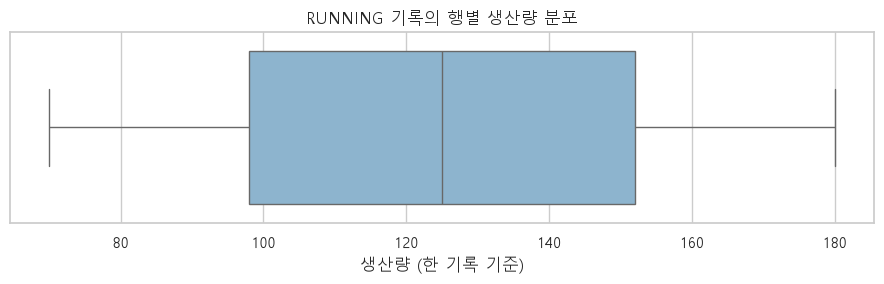

In [15]:
running_production = df.loc[df['operating_status'] == 'RUNNING', 'production_count'].dropna()
if running_production.empty:
    print('RUNNING 상태의 유효한 생산량 기록이 없습니다.')
else:
    plt.figure(figsize=(9, 3))
    sns.boxplot(x=running_production, color='#82b6d9')
    plt.title('RUNNING 기록의 행별 생산량 분포')
    plt.xlabel('생산량 (한 기록 기준)')
    plt.tight_layout()
    plt.show()

**결과 읽기:** 가운데 선과 상자의 양끝을 표의 중앙값·Q1·Q3와 비교해 보세요. 수염은 Q1−1.5×IQR과 Q3+1.5×IQR 범위에 있는 관측값 중 가장 바깥 값까지 표시됩니다. 그 밖의 점은 살펴볼 후보입니다.

### 4-3. 그래프로 분포 살펴보기

**이번에 할 일:** 생산량, 온도, 습도 값이 어디에 많이 모였는지 봅니다.

**AI에게 요청할 문장** — 아래 문장을 복사해서 바이브 코딩 도구에 입력할 수 있습니다. 이전 셀을 순서대로 실행한 상태라고 알려 주세요.

```text
생산량, 온도, 습도를 각각 히스토그램으로 그려 주세요.
```

**코드:** 아래 셀을 클릭하고 `Shift + Enter`를 누르세요.

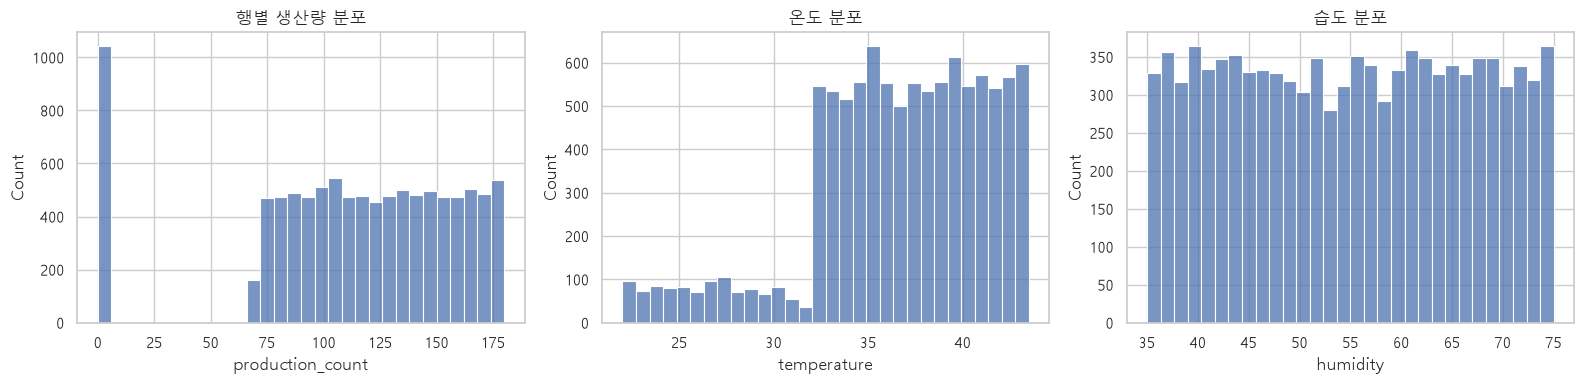

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(data=df, x='production_count', bins=30, ax=axes[0]); axes[0].set_title('행별 생산량 분포')
sns.histplot(data=df, x='temperature', bins=30, ax=axes[1]); axes[1].set_title('온도 분포')
sns.histplot(data=df, x='humidity', bins=30, ax=axes[2]); axes[2].set_title('습도 분포')
plt.tight_layout(); plt.show()

**결과 보는 법:** 히스토그램은 값을 구간별로 나눈 막대그래프입니다. 막대가 높을수록 그 구간에 속한 기록이 많습니다. 온도와 습도의 단위는 아직 확인되지 않았습니다.

## 5. 날짜와 시간에 따른 변화

같은 하루라도 기록이 일부 시간만 있으면 전체 하루와 공정하게 비교하기 어렵습니다.

### 5-1. 날짜별 표 만들기

**개념 한 걸음:** 집계는 같은 조건의 기록을 모아 합계나 평균을 구하는 것입니다. 예를 들어 같은 날짜의 생산 수량을 더해 일별 생산량을 만듭니다.

**이번에 할 일:** 날짜마다 생산량과 불량률을 계산합니다.

**AI에게 요청할 문장** — 아래 문장을 복사해서 바이브 코딩 도구에 입력할 수 있습니다. 이전 셀을 순서대로 실행한 상태라고 알려 주세요.

```text
df를 날짜별로 묶어 기록 수, 설비 수, 생산량, 불량 수와 가중 불량률을 계산해 daily에 저장하세요.
```

**코드:** 아래 셀을 클릭하고 `Shift + Enter`를 누르세요.

In [17]:
daily = df.groupby('date', dropna=False).agg(기록수=('machine_id','size'), 설비수=('machine_id','nunique'), 생산량=('production_count','sum'), 불량수=('defect_count','sum'))
daily['불량률(%)'] = daily['불량수'].div(daily['생산량'].where(daily['생산량'] > 0))*100
display(daily)

,기록수,설비수,생산량,불량수,불량률(%)
date,,,,,
2026-11-01,2400,100,270454,9295,3.437
2026-11-02,2400,100,269172,9125,3.390
2026-11-03,2400,100,266225,9098,3.417
2026-11-04,2400,100,267233,8963,3.354
2026-11-05,400,100,45492,1607,3.532


**결과 보는 법:** 마지막 날짜는 하루 전체가 아니라 일부 시간만 기록됐을 수 있습니다. 기록 수와 함께 비교하세요.

### 5-2. 시간대별 표 만들기

**이번에 할 일:** 오전과 오후의 각 시간대 기록을 모아 비교합니다.

**AI에게 요청할 문장** — 아래 문장을 복사해서 바이브 코딩 도구에 입력할 수 있습니다. 이전 셀을 순서대로 실행한 상태라고 알려 주세요.

```text
df를 시간대별로 묶어 기록 수, 생산량, 불량 수, 평균 온도와 가중 불량률을 hourly에 저장하세요.
```

**코드:** 아래 셀을 클릭하고 `Shift + Enter`를 누르세요.

In [18]:
hourly = df.groupby('hour').agg(기록수=('machine_id','size'), 생산량=('production_count','sum'), 불량수=('defect_count','sum'), 평균온도=('temperature','mean'))
hourly['불량률(%)'] = hourly['불량수'].div(hourly['생산량'].where(hourly['생산량'] > 0))*100
display(hourly)

,기록수,생산량,불량수,평균온도,불량률(%)
hour,,,,,
0,500,54701,1974,36.414,3.609
1,500,55829,1770,36.200,3.170
2,500,55288,1991,36.614,3.601
3,500,55963,1810,36.415,3.234
4,400,43727,1512,36.871,3.458
5,400,44770,1462,36.804,3.266
6,400,44669,1609,36.719,3.602
7,400,46826,1702,37.208,3.635
8,400,45409,1615,36.715,3.557


**결과 보는 법:** 각 시간대의 기록 수와 생산량이 서로 다를 수 있습니다. 불량률을 볼 때 생산량을 함께 확인하세요.

### 5-3. 날짜·시간·상태 그래프 보기

**이번에 할 일:** 앞에서 만든 표를 그래프로 바꿉니다.

**AI에게 요청할 문장** — 아래 문장을 복사해서 바이브 코딩 도구에 입력할 수 있습니다. 이전 셀을 순서대로 실행한 상태라고 알려 주세요.

```text
일별 생산량, 시간대별 불량률, 설비 상태별 관측 건수를 그래프로 그려 주세요.
```

**코드:** 아래 셀을 클릭하고 `Shift + Enter`를 누르세요.

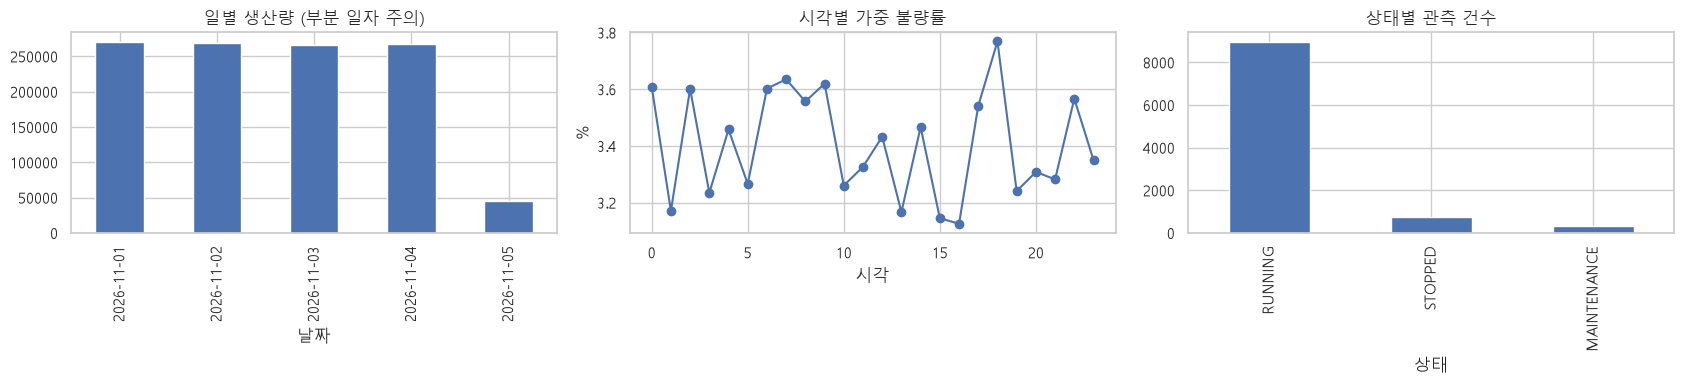

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
daily['생산량'].plot(kind='bar', ax=axes[0], title='일별 생산량 (부분 일자 주의)'); axes[0].set_xlabel('날짜')
hourly['불량률(%)'].plot(marker='o', ax=axes[1], title='시각별 가중 불량률'); axes[1].set_ylabel('%'); axes[1].set_xlabel('시각')
df.operating_status.value_counts().plot(kind='bar', ax=axes[2], title='상태별 관측 건수'); axes[2].set_xlabel('상태')
plt.tight_layout(); plt.show()

**결과 보는 법:** 막대와 선의 높이가 차이 나는 이유에는 기록 시간, 제품, 설비 차이가 섞여 있을 수 있습니다.

## 6. 라인과 설비 비교

라인은 설비가 배치된 생산 구역입니다. 설비별 불량률은 생산량도 함께 확인해야 합니다.

### 6-1. 라인과 설비별 표 만들기

**이번에 할 일:** 라인별 결과와 생산량·불량률 상위 설비를 확인합니다.

**AI에게 요청할 문장** — 아래 문장을 복사해서 바이브 코딩 도구에 입력할 수 있습니다. 이전 셀을 순서대로 실행한 상태라고 알려 주세요.

```text
라인과 설비별 기록 수, 생산량, 불량 수, 평균 온도, 온도 초과 비율과 가중 불량률을 집계하고 상위 설비를 보여 주세요.
```

**코드:** 아래 셀을 클릭하고 `Shift + Enter`를 누르세요.

In [20]:
def summarize(group):
    out = group.agg(기록수=('machine_id','size'), 설비수=('machine_id','nunique'), 생산량=('production_count','sum'), 불량수=('defect_count','sum'), 평균온도=('temperature','mean'), 온도초과비율=('temp_excess','mean'))
    out['불량률(%)'] = out['불량수'].div(out['생산량'].where(out['생산량'] > 0))*100
    out['온도초과비율'] *= 100
    return out
line = summarize(df.groupby('location', dropna=False))
by_machine = summarize(df.groupby(['machine_id','machine_name','location'], dropna=False))
display(line)
print('생산량 상위 설비 10대'); display(by_machine.sort_values('생산량', ascending=False).head(10))
print('불량률 상위 설비 10대: 생산량·기록수 함께 확인'); display(by_machine.sort_values('불량률(%)', ascending=False).head(10))

,기록수,설비수,생산량,불량수,평균온도,온도초과비율,불량률(%)
location,,,,,,,
A라인,5000,50,561818,18587,36.564,27.040,3.308
B라인,5000,50,556758,19501,36.652,27.860,3.503


생산량 상위 설비 10대


,,,기록수,설비수,생산량,불량수,평균온도,온도초과비율,불량률(%)
machine_id,machine_name,location,,,,,,,
M035,조립 17호기,B라인,100,1,12088,421,37.391,29.000,3.483
M094,프레스 48호기,A라인,100,1,12070,480,37.884,37.000,3.977
M070,프레스 36호기,A라인,100,1,12036,423,37.690,34.000,3.514
M010,프레스 6호기,A라인,100,1,12026,446,37.389,32.000,3.709
M082,프레스 42호기,A라인,100,1,11985,333,35.855,18.000,2.778
M077,프레스 39호기,A라인,100,1,11985,377,37.456,29.000,3.146
M099,조립 49호기,B라인,100,1,11961,390,36.328,27.000,3.261
M049,프레스 25호기,A라인,100,1,11950,347,36.253,21.000,2.904
M081,프레스 41호기,A라인,100,1,11918,365,36.795,24.000,3.063


불량률 상위 설비 10대: 생산량·기록수 함께 확인


,,,기록수,설비수,생산량,불량수,평균온도,온도초과비율,불량률(%)
machine_id,machine_name,location,,,,,,,
M100,조립 50호기,B라인,100,1,10715,443,37.059,32.000,4.134
M088,조립 44호기,B라인,100,1,11499,468,37.622,38.000,4.070
M031,조립 15호기,B라인,100,1,11640,467,37.244,30.000,4.012
M067,조립 33호기,B라인,100,1,10656,424,36.494,29.000,3.979
M094,프레스 48호기,A라인,100,1,12070,480,37.884,37.000,3.977
M024,조립 12호기,B라인,100,1,10848,431,36.389,31.000,3.973
M019,조립 9호기,B라인,100,1,11304,443,37.214,31.000,3.919
M039,조립 19호기,B라인,100,1,10999,428,36.556,25.000,3.891
M074,프레스 38호기,A라인,100,1,10906,419,36.502,28.000,3.842


**결과 보는 법:** 생산량이 적으면 불량 한 개만 생겨도 불량률이 크게 바뀝니다. 제품과 작업 조건도 달라 순위만으로 설비 성능을 단정할 수 없습니다.

### 6-2. 라인과 설비 그래프 보기

**이번에 할 일:** 라인별 불량률과 설비별 생산량·불량률을 시각화합니다.

**AI에게 요청할 문장** — 아래 문장을 복사해서 바이브 코딩 도구에 입력할 수 있습니다. 이전 셀을 순서대로 실행한 상태라고 알려 주세요.

```text
라인별 불량률 막대그래프와 설비별 생산량·불량률 산점도를 그려 주세요.
```

**코드:** 아래 셀을 클릭하고 `Shift + Enter`를 누르세요.

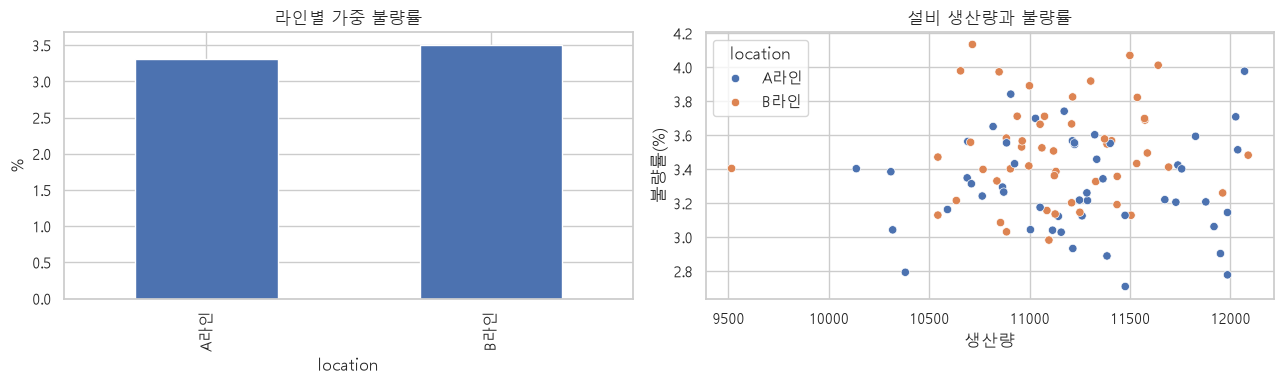

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
line['불량률(%)'].plot(kind='bar', ax=axes[0], title='라인별 가중 불량률'); axes[0].set_ylabel('%')
sns.scatterplot(data=by_machine.reset_index(), x='생산량', y='불량률(%)', hue='location', ax=axes[1]); axes[1].set_title('설비 생산량과 불량률')
plt.tight_layout(); plt.show()

**결과 보는 법:** 오른쪽 산점도에서 점 하나는 설비 하나입니다. 오른쪽일수록 생산량이 많고, 위쪽일수록 불량률이 높습니다.

## 7. 온도와 불량률의 관계

온도가 설비별 한계보다 높았을 때 불량률이 다른지 비교합니다. 두 값이 함께 변해도 한쪽이 다른 쪽의 원인이라고 바로 결론 낼 수 없습니다.

### 7-1. 온도에 따라 두 그룹 만들기

**이번에 할 일:** 한계 이하와 한계 초과 기록을 비교합니다.

**AI에게 요청할 문장** — 아래 문장을 복사해서 바이브 코딩 도구에 입력할 수 있습니다. 이전 셀을 순서대로 실행한 상태라고 알려 주세요.

```text
생산량이 양수이고 온도·한계값이 있는 기록을 온도 한계 이하와 초과로 나누고 각 그룹의 생산량, 불량 수, 가중 불량률을 계산하세요.
```

**코드:** 아래 셀을 클릭하고 `Shift + Enter`를 누르세요.

In [22]:
valid = df[(df.production_count > 0) & df.temperature.notna() & df.temperature_limit.notna() & df.defect_count.notna()].copy()
valid['온도군'] = np.where(valid.temperature > valid.temperature_limit, '한계 초과', '한계 이하')
temp_group = valid.groupby('온도군').agg(기록수=('machine_id','size'), 설비수=('machine_id','nunique'), 생산량=('production_count','sum'), 불량수=('defect_count','sum'))
temp_group['불량률(%)'] = temp_group['불량수'] / temp_group['생산량'] * 100
display(temp_group)

,기록수,설비수,생산량,불량수,불량률(%)
온도군,,,,,
한계 이하,6213,100,774611,16383,2.115
한계 초과,2745,100,343965,21705,6.310


**결과 보는 법:** 불량률은 각 그룹의 불량 합을 생산 합으로 나눈 값입니다. 온도 외에 제품과 설비 같은 다른 차이도 영향을 줄 수 있습니다.

### 7-2. 온도와 불량률 그래프 보기

**이번에 할 일:** 두 그룹의 불량률과 개별 기록의 관계를 그립니다.

**AI에게 요청할 문장** — 아래 문장을 복사해서 바이브 코딩 도구에 입력할 수 있습니다. 이전 셀을 순서대로 실행한 상태라고 알려 주세요.

```text
온도 그룹별 불량률 막대그래프와 온도·행별 불량률 산점도를 표시하세요. 산점도는 최대 2,500행만 보여 주세요.
```

**코드:** 아래 셀을 클릭하고 `Shift + Enter`를 누르세요.

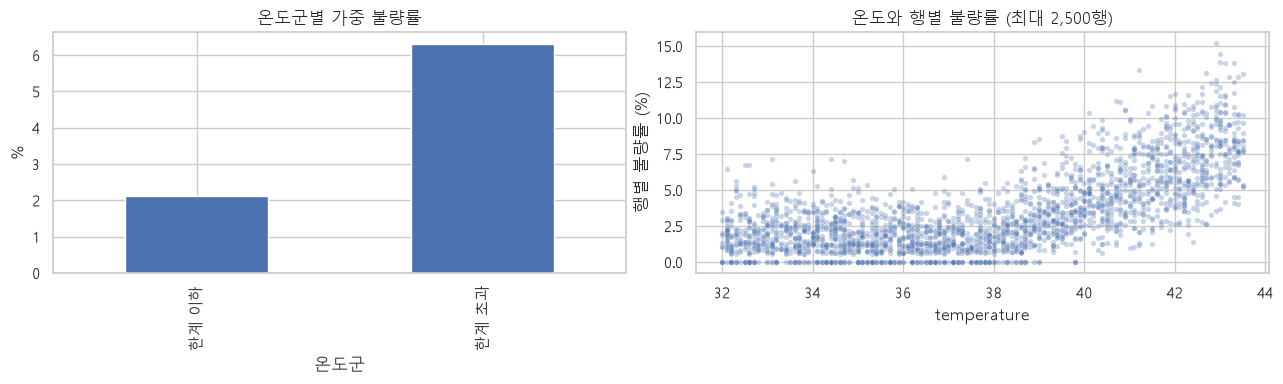

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
temp_group['불량률(%)'].plot(kind='bar', ax=axes[0], title='온도군별 가중 불량률'); axes[0].set_ylabel('%')
sns.scatterplot(data=valid.sample(min(len(valid), 2500), random_state=42), x='temperature', y='row_defect_rate', alpha=.3, s=15, ax=axes[1]); axes[1].set_title('온도와 행별 불량률 (최대 2,500행)'); axes[1].set_ylabel('행별 불량률 (%)')
plt.tight_layout(); plt.show()

**결과 보는 법:** 막대의 차이는 두 그룹의 불량률 차이입니다. 산점도에서는 점 하나가 기록 한 건이며, 표시된 점은 전체의 일부일 수 있습니다.

### 7-3. 함께 변하는 정도 계산하기

**개념 한 걸음:** 상관관계는 두 숫자가 함께 변하는 경향입니다. 여름에 아이스크림 판매량과 기온이 함께 높아도, 판매가 기온을 올린다고 할 수는 없습니다. 상관관계만으로 원인을 알 수 없습니다.

**이번에 할 일:** 온도와 불량률이 같은 방향으로 움직이는지 확인합니다.

**AI에게 요청할 문장** — 아래 문장을 복사해서 바이브 코딩 도구에 입력할 수 있습니다. 이전 셀을 순서대로 실행한 상태라고 알려 주세요.

```text
생산량이 양수인 기록의 온도와 행별 불량률에 대한 Spearman 상관계수와 명목 p값을 계산하세요. 같은 설비의 반복 기록 때문에 p값은 참고용이라고 설명하세요.
```

**코드:** 아래 셀을 클릭하고 `Shift + Enter`를 누르세요.

In [24]:
if len(valid) >= 3 and valid.temperature.nunique() > 1 and valid.row_defect_rate.nunique() > 1:
    rho, p = stats.spearmanr(valid.temperature, valid.row_defect_rate, nan_policy='omit')
    print(f'행 단위 Spearman 상관계수: {rho:.3f}, 명목 p값: {p:.3g}')
    print('p값은 반복 관측을 독립으로 취급하므로 참고용이며, 인과관계나 설비 단위 유의성의 증거가 아닙니다.')

행 단위 Spearman 상관계수: 0.669, 명목 p값: 0
p값은 반복 관측을 독립으로 취급하므로 참고용이며, 인과관계나 설비 단위 유의성의 증거가 아닙니다.


**결과 보는 법:** 상관계수는 -1부터 1까지입니다. 1에 가까우면 같은 방향, -1에 가까우면 반대 방향입니다. p값도 원인을 증명하지 않으며, 여기서는 반복 기록을 독립으로 취급해 참고용입니다.

## 8. 조금 더 알아보기: 통계 분석

여기는 선택 학습입니다. 처음에는 결과 설명을 읽고 넘어가도 됩니다. 아래 분석은 결론의 확실성을 생각해 보는 데 도움을 줍니다.

### 8-1. 부트스트랩으로 차이 범위 살펴보기

**개념 한 걸음:** 부트스트랩은 관측한 설비를 제비뽑기처럼 중복을 허용해 다시 뽑고 계산을 반복하는 방법입니다. 이때 각 설비의 기록은 한 묶음으로 뽑습니다.

**이번에 할 일:** 설비를 여러 번 다시 뽑아 온도 그룹의 불량률 차이를 계산합니다.

**AI에게 요청할 문장** — 아래 문장을 복사해서 바이브 코딩 도구에 입력할 수 있습니다. 이전 셀을 순서대로 실행한 상태라고 알려 주세요.

```text
설비 단위로 2,000회 복원 추출하여 온도 초과군과 이하군의 가중 불량률 차이와 95% 부트스트랩 구간을 계산하세요. 시드는 42로 고정하고 분모가 0인 표본은 제외하세요.
```

**코드:** 아래 셀을 클릭하고 `Shift + Enter`를 누르세요.

In [25]:
wide = valid.pivot_table(index='machine_id', columns='온도군', values=['production_count','defect_count'], aggfunc='sum', fill_value=0)
required = pd.MultiIndex.from_product([['production_count','defect_count'], ['한계 이하','한계 초과']])
wide = wide.reindex(columns=required, fill_value=0)
arr = wide.to_numpy(dtype=float)
if len(arr) and {'한계 이하','한계 초과'}.issubset(set(valid['온도군'])):
    def difference(a):
        totals = a.sum(axis=0)
        return 100*(totals[3]/totals[1] - totals[2]/totals[0]) if totals[0] > 0 and totals[1] > 0 else np.nan
    rng = np.random.default_rng(42)
    samples = np.array([difference(arr[rng.integers(0, len(arr), len(arr))]) for _ in range(2000)])
    finite = samples[np.isfinite(samples)]
    if len(finite):
        lo, hi = np.percentile(finite, [2.5, 97.5])
        print(f'관측 차이: {difference(arr):.3f}%p / 95% 부트스트랩 구간: [{lo:.3f}, {hi:.3f}]%p / 유효 반복: {len(finite):,}회')
    else:
        print('유효한 부트스트랩 표본이 없어 구간을 계산할 수 없습니다.')
else:
    print('두 온도군의 생산 관측이 모두 필요합니다.')

관측 차이: 4.195%p / 95% 부트스트랩 구간: [4.097, 4.296]%p / 유효 반복: 2,000회


**결과 보는 법:** 예를 들어 3%와 5%의 차이는 2%포인트(%p)입니다. 표시된 구간은 관측된 설비를 반복해서 뽑을 때 차이가 얼마나 달라지는지 보여 줍니다. 설비가 대표적이고 서로 독립적이라는 가정이 필요하며, 공통 시간 효과와 다른 조건의 영향은 제거하지 못합니다.

### 8-2. 여러 숫자의 관계 보기

**이번에 할 일:** 생산량, 불량, 온도, 습도의 관계를 색깔 표로 확인합니다.

**AI에게 요청할 문장** — 아래 문장을 복사해서 바이브 코딩 도구에 입력할 수 있습니다. 이전 셀을 순서대로 실행한 상태라고 알려 주세요.

```text
생산량이 양수인 기록의 수치형 변수에 대해 Spearman 상관행렬을 계산하고 색깔 표로 표시해 주세요.
```

**코드:** 아래 셀을 클릭하고 `Shift + Enter`를 누르세요.

,production_count,defect_count,temperature,humidity,row_defect_rate
production_count,1.000,0.305,0.008,-0.010,0.034
defect_count,0.305,1.000,0.637,0.150,0.955
temperature,0.008,0.637,1.000,0.008,0.669
humidity,-0.010,0.150,0.008,1.000,0.159
row_defect_rate,0.034,0.955,0.669,0.159,1.000


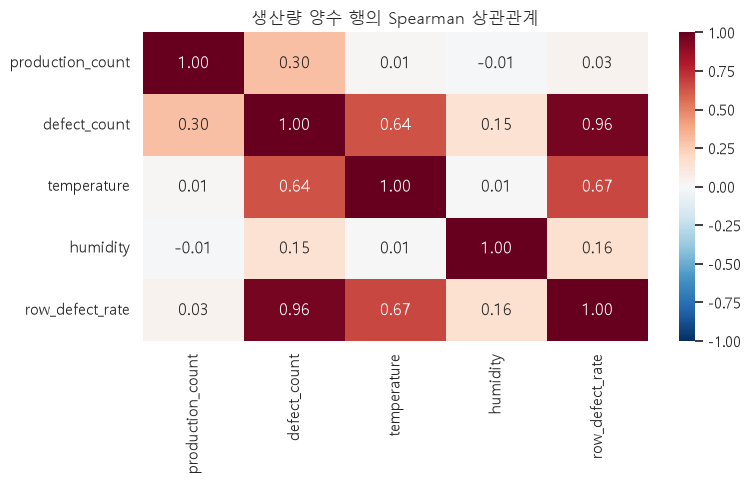

In [26]:
cols = ['production_count','defect_count','temperature','humidity','row_defect_rate']
corr = valid[cols].corr(method='spearman')
display(corr)
plt.figure(figsize=(8,5)); sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1); plt.title('생산량 양수 행의 Spearman 상관관계'); plt.tight_layout(); plt.show()

**결과 보는 법:** 표의 수가 0에 가까우면 뚜렷한 순위 관계가 약합니다. 여러 관계를 동시에 살피면 우연히 눈에 띄는 값도 나올 수 있습니다.

### 8-3. 눈에 띄는 값 찾기

**이번에 할 일:** 다른 기록보다 특히 크거나 작은 값의 후보를 셉니다.

**AI에게 요청할 문장** — 아래 문장을 복사해서 바이브 코딩 도구에 입력할 수 있습니다. 이전 셀을 순서대로 실행한 상태라고 알려 주세요.

```text
생산량이 양수인 기록에서 각 변수의 IQR을 계산하고 1.5 IQR 기준 밖에 있는 후보의 수를 보여 주세요.
```

**코드:** 아래 셀을 클릭하고 `Shift + Enter`를 누르세요.

In [27]:
outlier_rows = []
for col in ['temperature', 'humidity', 'production_count', 'row_defect_rate']:
    series = valid[col].dropna()
    q1, q3 = series.quantile([.25,.75]); iqr = q3-q1
    outlier_rows.append({'변수':col, '하한':q1-1.5*iqr, '상한':q3+1.5*iqr, '후보 건수':((series<q1-1.5*iqr)|(series>q3+1.5*iqr)).sum(), '유효 건수':len(series)})
display(pd.DataFrame(outlier_rows).set_index('변수'))

,하한,상한,후보 건수,유효 건수
변수,,,,
temperature,26.200,49.400,0,8958
humidity,14.200,95.800,0,8958
production_count,17.000,233.000,0,8958
row_defect_rate,-4.049,10.234,208,8958


**결과 보는 법:** IQR은 전체 값을 크기순으로 정렬했을 때 가운데 절반이 차지하는 범위의 폭입니다. 그 범위에서 멀리 떨어져도 반드시 오류나 고장은 아닙니다.

## 9. 분석을 프로그램에 연결하기

### 9-1. 핵심 결과 한 번에 보기

**이번에 할 일:** 지금까지의 주요 결과를 한글로 정리합니다.

**AI에게 요청할 문장** — 아래 문장을 복사해서 바이브 코딩 도구에 입력할 수 있습니다. 이전 셀을 순서대로 실행한 상태라고 알려 주세요.

```text
분석된 기간, 등록·관측 설비 수, 생산량, 불량률, RUNNING 관측 비율, 온도 초과 비율과 주요 품질 점검 결과를 한글로 요약해 주세요. 부분 날짜와 시간대 미확인을 표시하세요.
```

**코드:** 아래 셀을 클릭하고 `Shift + Enter`를 누르세요.

In [28]:
observed = df.machine_id.nunique(); master_count = machine.machine_id.nunique()
last_day = daily.index.max()
summary = f"""### 현재 데이터에서 확인한 내용
- 마스터 설비 **{master_count:,}대**, 이력이 있는 설비 **{observed:,}대**, 이력 없는 마스터 **{master_count-observed:,}대**입니다. 이력 없음은 미수집 또는 미가동 중 어느 쪽인지 확인할 수 없습니다.
- 생산 기록은 **{len(df):,}건**, 기간은 **{df.timestamp_parsed.min()} ~ {df.timestamp_parsed.max()}**이며 시간대는 미확인입니다.
- 가정에 따른 총 생산량은 **{total_prod:,.0f}**, 불량 수는 **{total_def:,.0f}**, 가중 불량률은 **{overall_rate:.2f}%**입니다.
- RUNNING **관측 비율**은 **{df.operating_status.eq('RUNNING').mean()*100:.2f}%**이고 온도 한계 초과 **관측 비율**은 **{df.temp_excess.mean()*100:.2f}%**입니다.
- 마지막 날짜 **{last_day}**의 일별 집계는 부분 날짜일 가능성이 있으므로 다른 날짜와 단순 비교하지 않습니다.
- 품질 점검에서 마스터 키 중복 **{checks['마스터 설비 ID 중복']:,}건**, 미매칭 생산 행 **{checks['마스터에 없는 생산 행']:,}건**, 시각·설비 중복 **{checks['시각·설비 중복']:,}건**입니다.
"""
display(Markdown(summary))

### 현재 데이터에서 확인한 내용
- 마스터 설비 **10,000대**, 이력이 있는 설비 **100대**, 이력 없는 마스터 **9,900대**입니다. 이력 없음은 미수집 또는 미가동 중 어느 쪽인지 확인할 수 없습니다.
- 생산 기록은 **10,000건**, 기간은 **2026-11-01 00:00:00 ~ 2026-11-05 03:00:00**이며 시간대는 미확인입니다.
- 가정에 따른 총 생산량은 **1,118,576**, 불량 수는 **38,088**, 가중 불량률은 **3.41%**입니다.
- RUNNING **관측 비율**은 **89.58%**이고 온도 한계 초과 **관측 비율**은 **27.45%**입니다.
- 마지막 날짜 **2026-11-05**의 일별 집계는 부분 날짜일 가능성이 있으므로 다른 날짜와 단순 비교하지 않습니다.
- 품질 점검에서 마스터 키 중복 **0건**, 미매칭 생산 행 **0건**, 시각·설비 중복 **0건**입니다.


**결과 보는 법:** 이 숫자를 프로그램의 요약 카드에 사용할 수 있습니다. 숫자 옆에 조회 기간과 계산 방법도 함께 보여 주어야 합니다.

### 9-2. 어떤 화면을 만들면 좋을까?

| 화면 | 보여 줄 내용 |
|---|---|
| 공장 전체 | 생산량, 불량률, 온도 초과 관측 건수 |
| 설비 목록 | 설비 이름, 라인, 마지막 기록 시각과 상태 |
| 설비 상세 | 선택한 설비의 생산량과 온도 변화 |
| 데이터 점검 | 값이 비어 있거나 중복된 기록의 후보 |

### 9-3. 프로그램을 만들기 전 확인할 질문

1. 생산량은 **그 시간에 새로 만든 수량**인가요, 아니면 처음부터 계속 더한 **누적 수량**인가요?
2. 불량 수량은 생산량에 포함되나요?
3. 기록 시각의 시간대와 수집 간격은 무엇인가요? 온도와 습도의 단위는 무엇인가요?
4. 이력이 없는 설비는 미사용인가요, 아니면 데이터가 수집되지 않은 건가요?
5. 온도 초과가 얼마나 지속될 때 알림을 보내고, 언제 해제해야 하나요?

이 답이 정해지면 계산식과 화면 설명을 현장 기준에 맞게 고칩니다. 기록만으로 실제 가동 시간이나 OEE를 계산하려면 계획 시간과 정지 지속 시간 등 추가 데이터가 필요합니다.


## 10. 프로그램 제작용 바이브 코딩 프롬프트
아래 프롬프트를 순서대로 코딩 도구에 전달하세요. 먼저 이 노트북과 두 CSV를 함께 읽게 하고, 각 단계의 실행 결과를 확인한 후 다음 단계로 넘어가면 수정 범위를 줄일 수 있습니다. 기술 스택은 시작하기 쉬운 **Python + Streamlit + pandas + Plotly** 제안이며 필요하면 바꾸어도 됩니다.

### 프롬프트 1 — 프로젝트 설계와 데이터 계층
```text
당신은 제조 데이터 분석가이자 Python 풀스택 개발자입니다. 현재 폴더의 machine_info.csv, production_data.csv와 데이터분석.ipynb를 먼저 읽고, 노트북의 실제 분석 결과와 지표 정의를 기준으로 스마트 팩토리 모니터링 앱을 만들어 주세요.

1. Python, Streamlit, pandas, Plotly를 사용하고 로컬 CSV로 실행 가능한 MVP를 구성하세요. requirements.txt와 실행 방법이 담긴 README를 작성하세요.
2. CSV의 실제 열과 데이터 타입을 확인하고 machine_id로 many-to-one left join하세요. 마스터 키 중복 시 의미 있는 오류를 표시하고, 미매칭 생산 행은 보존하고 별도 건수로 표시하세요. 원본 CSV는 수정하지 마세요.
3. timestamp를 안전하게 파싱하고 변환 실패, 결측, 중복, 음수, 불량 > 생산, 비가동 상태의 생산량, 미매칭을 데이터 품질 화면에 보여 주세요. timestamp+machine_id 중복은 자동 삭제하지 말고 제품 단위 중복도 보여 주세요.
4. 구간 생산량이고 불량이 생산량에 포함된다는 가정으로 총 생산량과 불량률(불량 합/생산 합)을 계산하세요. 분모 0은 0%가 아니라 '계산 불가'로 표시하세요. 이 가정과 시간대 미확인 사실을 화면과 README에 명시하세요.
5. 관측 대상 설비와 전체 마스터 설비를 구분하고, 이력 없는 설비는 '이력 없음'으로 표시하세요. RUNNING 행 비율은 'RUNNING 관측 비율'로 표시하고 실제 시간 가동률이나 OEE로 명명하지 마세요.
6. 온도 > 해당 설비 temperature_limit을 초과로 정의하고 한계값 자체는 초과에 포함하지 마세요. 데이터 단위는 확인 전 임의로 확정하지 마세요. 필터와 지표 계산 함수를 분리하고, 샘플 데이터와 경계값으로 핵심 계산을 검증하세요.
설계 요약과 파일 구조를 설명한 다음 구현하고 실제 실행 및 테스트 결과를 알려 주세요. 확인되지 않은 값은 지어내지 마세요.
```

### 프롬프트 2 — 대시보드와 탐색
```text
앞 단계의 데이터 계층과 데이터분석.ipynb를 기반으로 화면을 구현해 주세요.
- 기간, 라인, 설비, 상태, 제품 필터를 제공하고 모든 KPI와 차트가 동일한 필터 결과를 사용하게 해 주세요. 전체 마스터 수와 관측 설비 수는 모집단을 명확히 표시해 주세요.
- 개요에는 총 생산, 총 불량, 가중 불량률, RUNNING 관측 비율, 유효 온도 관측 중 한계 초과 비율을 표시하고 각 분자·분모를 설명해 주세요.
- 일별 생산·불량률, 시간별 가중 불량률, 라인별 비교와 설비 목록을 구현하세요. 부분 날짜, 데이터 없음, 분모 0을 구분하고 기록 수를 함께 보여 주세요.
- 설비 상세에는 최신 기록 시각, 최신 관측 상태, 온도와 설비별 한계, 생산·불량·온도 추이를 표시하세요. 최신 기록이 오래된 경우 현재 상태로 단정하지 마세요.
- 온도 초과 관측 목록과 데이터 품질 화면을 제공하세요. 실제 실시간 데이터나 메시지 발송은 구현되었다고 주장하지 마세요.
- 한글이 읽기 쉬운 반응형 UI를 만들고, 빈 필터 결과와 온도 한계 누락을 처리하세요. 샘플을 실행하여 필터, 합계, 비율과 차트가 일치하는지 확인하세요.
```

### 프롬프트 3 — 검증과 개선
```text
완성된 앱을 데이터분석.ipynb의 결과와 비교 검증해 주세요. 필터를 해제한 전체 생산량, 불량 수, 가중 불량률, 관측 설비 수, 마스터 수, 온도 초과 건수를 독립적으로 계산해 화면과 비교하세요. 분모 0, 키 중복, 미매칭, 중복 기록, 온도=한계, 결측값, 빈 검색 결과를 점검하세요. 발견한 문제를 수정하고 테스트 명령과 실제 결과를 보고해 주세요. 마지막으로 운영 도입 전 확인할 수량 정의, 시간대, 데이터 수집 주기와 알림 정책을 README에 정리해 주세요.
```

### 다음 분석 제안
더 긴 기간의 설비별 기록과 제품·작업조·보전 이력을 확보해, 동일 설비의 조건 변화와 시간 효과를 고려한 분석을 진행하세요. 모델 검증은 시간 순서로 학습·검증 기간을 분리하고, 예측 시점 이후에만 알 수 있는 정보를 입력에 넣지 않아야 합니다. 고장 라벨이나 실제 이벤트 시각이 없으므로 현재 데이터만으로 고장 예측 정확도를 평가할 수 없습니다.